In [7]:
##检查环境，加载数据

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.9
NumPy: 2.3.5
pandas: 2.3.3
scikit-learn: 1.7.2


In [2]:
from sklearn.datasets import load_iris

# Load the dataset as pandas objects.
iris = load_iris(as_frame=True)

# Separate input features from target labels.
X = iris.data
y = iris.target

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("Feature names:", X.columns.tolist())
print("Class names:", iris.target_names)

display(X.head())
display(y.head())

Feature matrix shape: (150, 4)
Target vector shape: (150,)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Class names: ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

In [3]:
# Create a separate table for data inspection.
df = X.copy()

# Map numeric labels to readable class names.
label_to_name = dict(enumerate(iris.target_names))
df["label"] = y
df["species"] = y.map(label_to_name)

display(df.head())

print("Samples per class:")
print(df["species"].value_counts())

print("\nMissing values per column:")
print(df.isna().sum())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),label,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


Samples per class:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Missing values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
label                0
species              0
dtype: int64


In [6]:
##划分训练和测试

In [4]:
from sklearn.model_selection import train_test_split

# Use a fixed random seed for reproducibility.
RANDOM_SEED = 42

# Split the data while preserving class proportions.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=y,
)

print("Training feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Test target shape:", y_test.shape)

print("\nTraining samples per class:")
print(y_train.value_counts().sort_index())

print("\nTest samples per class:")
print(y_test.value_counts().sort_index())

Training feature shape: (120, 4)
Test feature shape: (30, 4)
Training target shape: (120,)
Test target shape: (30,)

Training samples per class:
target
0    40
1    40
2    40
Name: count, dtype: int64

Test samples per class:
target
0    10
1    10
2    10
Name: count, dtype: int64


In [5]:
# Verify that training and test samples do not overlap.
overlapping_indices = X_train.index.intersection(X_test.index)

print("Number of overlapping samples:", len(overlapping_indices))

assert len(overlapping_indices) == 0
assert len(X_train) + len(X_test) == len(X)

print("Split checks passed.")

Number of overlapping samples: 0
Split checks passed.


In [8]:
##逻辑回归

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Combine feature scaling and classification.
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=1000,
    )),
])

# Learn scaling statistics and model parameters from training data.
logistic_model.fit(X_train, y_train)


,steps,"[('scaler', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [11]:
from sklearn.metrics import accuracy_score

# Predict labels using the fitted pipeline.
y_train_pred = logistic_model.predict(X_train)
y_test_pred = logistic_model.predict(X_test)

# Calculate accuracy on training and test data.
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training accuracy: {train_accuracy:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Correct test predictions: {(y_test_pred == y_test).sum()} / {len(y_test)}")

Training accuracy: 0.9583
Test accuracy: 0.9333
Correct test predictions: 28 / 30


Confusion matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


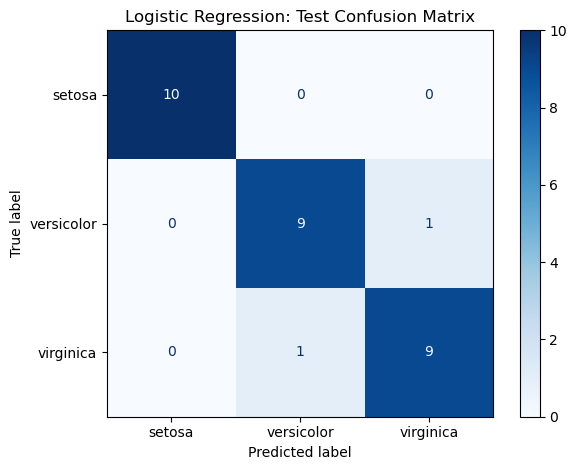

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Fix the class order for both rows and columns.
class_labels = [0, 1, 2]

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=class_labels,
)

print("Confusion matrix:")
print(cm)

# Display the confusion matrix with readable class names.
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names,
).plot(cmap="Blues")

plt.title("Logistic Regression: Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [13]:
##KNN

In [14]:
from sklearn.neighbors import KNeighborsClassifier

# Combine feature scaling and nearest-neighbor classification.
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        metric="euclidean",
    )),
])

# Store the training data after scaling.
knn_model.fit(X_train, y_train)


,steps,"[('scaler', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30


Training accuracy: 0.9750
Test accuracy: 0.9333

Confusion matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


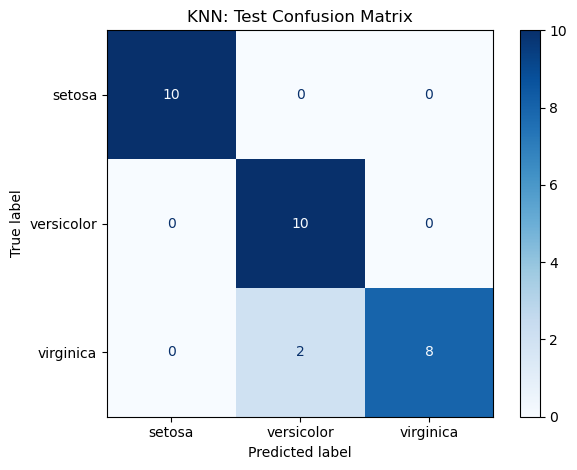

In [15]:
# Predict labels for training and test samples.
knn_train_pred = knn_model.predict(X_train)
knn_test_pred = knn_model.predict(X_test)

# Calculate training and test accuracy.
knn_train_accuracy = accuracy_score(y_train, knn_train_pred)
knn_test_accuracy = accuracy_score(y_test, knn_test_pred)

print(f"Training accuracy: {knn_train_accuracy:.4f}")
print(f"Test accuracy: {knn_test_accuracy:.4f}")

# Calculate and display the test confusion matrix.
knn_cm = confusion_matrix(
    y_test,
    knn_test_pred,
    labels=class_labels,
)

print("\nConfusion matrix:")
print(knn_cm)

ConfusionMatrixDisplay(
    confusion_matrix=knn_cm,
    display_labels=iris.target_names,
).plot(cmap="Blues")

plt.title("KNN: Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [16]:
# Compare both models using the same data split.
comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Training accuracy": train_accuracy,
        "Test accuracy": test_accuracy,
    },
    {
        "Model": "KNN (k=5)",
        "Training accuracy": knn_train_accuracy,
        "Test accuracy": knn_test_accuracy,
    },
])

display(comparison.round(4))

,Model,Training accuracy,Test accuracy
0,Logistic Regression,0.9583,0.9333
1,KNN (k=5),0.9750,0.9333


In [17]:
##decision tree

In [19]:
from sklearn.tree import DecisionTreeClassifier

# Train a decision tree without a maximum depth limit.
tree_model = DecisionTreeClassifier(
    max_depth=None,
    random_state=RANDOM_SEED,
)

tree_model.fit(X_train, y_train)

print("Tree depth:", tree_model.get_depth())
print("Number of leaves:", tree_model.get_n_leaves())

Tree depth: 5
Number of leaves: 8


Training accuracy: 1.0000
Test accuracy: 0.9333

Confusion matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


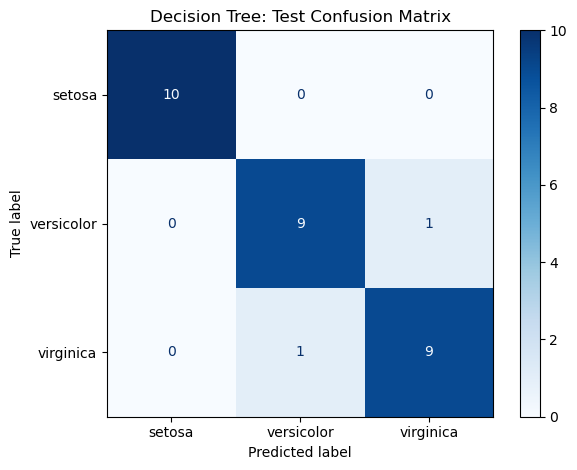

In [20]:
# Predict labels for training and test samples.
tree_train_pred = tree_model.predict(X_train)
tree_test_pred = tree_model.predict(X_test)

# Calculate training and test accuracy.
tree_train_accuracy = accuracy_score(y_train, tree_train_pred)
tree_test_accuracy = accuracy_score(y_test, tree_test_pred)

print(f"Training accuracy: {tree_train_accuracy:.4f}")
print(f"Test accuracy: {tree_test_accuracy:.4f}")

# Calculate and display the test confusion matrix.
tree_cm = confusion_matrix(
    y_test,
    tree_test_pred,
    labels=class_labels,
)

print("\nConfusion matrix:")
print(tree_cm)

ConfusionMatrixDisplay(
    confusion_matrix=tree_cm,
    display_labels=iris.target_names,
).plot(cmap="Blues")

plt.title("Decision Tree: Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [21]:
# Compare all three models on the same training and test sets.
comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Training accuracy": train_accuracy,
        "Test accuracy": test_accuracy,
    },
    {
        "Model": "KNN (k=5)",
        "Training accuracy": knn_train_accuracy,
        "Test accuracy": knn_test_accuracy,
    },
    {
        "Model": "Decision Tree",
        "Training accuracy": tree_train_accuracy,
        "Test accuracy": tree_test_accuracy,
    },
])

display(comparison.round(4))

,Model,Training accuracy,Test accuracy
0,Logistic Regression,0.9583,0.9333
1,KNN (k=5),0.9750,0.9333
2,Decision Tree,1.0000,0.9333


Question1 Why should we not evaluate a model only using training data?

模型已经学习了训练集的数据特征和分类规则，因此训练auc会偏好。单用训练结果无法判断模型在未遇见数据上的表现

Question2 What is overfitting?

模型过度学习训练集的数据特征，甚至连噪声也学习了，导致模型在训练集上表现很好，但在新数据上表现较差

Question3 What happens if a decision tree becomes too deep?

树越深，就能进行更细的划分，深的节点会用更少的样本判断预测，这通常会提高训练auc，但也更多的捕捉噪声，增加过拟合风险

Question4 Why do we need a test set?

测试集用来评估模型对于新数据的泛化能力。

In [22]:
# Collect true labels and predictions for each test sample.
prediction_details = pd.DataFrame(
    {
        "True label": y_test,
        "Logistic Regression": y_test_pred,
        "KNN": knn_test_pred,
        "Decision Tree": tree_test_pred,
    },
    index=y_test.index,
)

model_columns = [
    "Logistic Regression",
    "KNN",
    "Decision Tree",
]

# Select samples misclassified by at least one model.
error_mask = prediction_details[model_columns].ne(
    prediction_details["True label"],
    axis="index",
).any(axis=1)

# Replace numeric class labels with readable names.
error_details = prediction_details.loc[error_mask].copy()

for column in error_details.columns:
    error_details[column] = error_details[column].map(label_to_name)

print("Test samples misclassified by at least one model:")
display(error_details)

Test samples misclassified by at least one model:


,True label,Logistic Regression,KNN,Decision Tree
138,virginica,virginica,versicolor,virginica
134,virginica,versicolor,versicolor,versicolor
77,versicolor,virginica,versicolor,virginica


实验观察

三个模型的测试auc都是93.33%，都错了两个样本，但错误样本不完全相同。且错误都发生在versicolor和virginica之间，说明这两类在当前特征下可能更难区分。

In [23]:
# Record the main settings and results of each experiment.
experiment_records = pd.DataFrame([
    {
        "Experiment": "iris_logistic_regression",
        "Model": "Logistic Regression",
        "Input representation": "4 standardized numeric features",
        "Main hyperparameters": "C=1.0, solver=lbfgs, max_iter=1000",
        "Random seed": RANDOM_SEED,
        "Training loss": "Not recorded; no loss curve exposed by this estimator",
        "Training accuracy": train_accuracy,
        "Test accuracy": test_accuracy,
        "Observations": "Misclassified samples 134 and 77.",
    },
    {
        "Experiment": "iris_knn",
        "Model": "KNN",
        "Input representation": "4 standardized numeric features",
        "Main hyperparameters": "n_neighbors=5, weights=uniform, metric=euclidean",
        "Random seed": RANDOM_SEED,
        "Training loss": "N/A; no iterative loss minimization",
        "Training accuracy": knn_train_accuracy,
        "Test accuracy": knn_test_accuracy,
        "Observations": "Misclassified samples 138 and 134.",
    },
    {
        "Experiment": "iris_decision_tree",
        "Model": "Decision Tree",
        "Input representation": "4 original numeric features",
        "Main hyperparameters": "max_depth=None, criterion=gini",
        "Random seed": RANDOM_SEED,
        "Training loss": "N/A; uses local impurity reduction",
        "Training accuracy": tree_train_accuracy,
        "Test accuracy": tree_test_accuracy,
        "Observations": "Perfect training accuracy; misclassified samples 134 and 77.",
    },
])

display(experiment_records)

,Experiment,Model,Input representation,Main hyperparameters,Random seed,Training loss,Training accuracy,Test accuracy,Observations
0,iris_logistic_regression,Logistic Regression,4 standardized numeric features,"C=1.0, solver=lbfgs, max_iter=1000",42,Not recorded; no loss curve exposed by this es...,0.958333,0.933333,Misclassified samples 134 and 77.
1,iris_knn,KNN,4 standardized numeric features,"n_neighbors=5, weights=uniform, metric=euclidean",42,N/A; no iterative loss minimization,0.975000,0.933333,Misclassified samples 138 and 134.
2,iris_decision_tree,Decision Tree,4 original numeric features,"max_depth=None, criterion=gini",42,N/A; uses local impurity reduction,1.000000,0.933333,Perfect training accuracy; misclassified sampl...
